# Processamento de Sinais Multimédia (PSM) — TP1
## Parte A — Equalizador FIR Multi-Banda e Análise Frequencial

**Licenciatura em Engenharia Informática e Multimédia (LEIM) — ISEL** · Ano letivo 2026/2027

**Grupo:** 49774 · 51811

---

Este notebook implementa a **Parte A** do TP1, ou seja, um equalizador gráfico de 3 bandas feito com filtros FIR projetados pelo método das janelas (`scipy.signal.firwin`). Contém também a análise frequencial pedida na secção 3.1 do enunciado.

O equalizador recebe um sinal $x[n]$ amostrado a $F_s = 44100$ Hz e divide-o em três bandas:

| Banda | Tipo de filtro | Frequências de corte |
| :--- | :--- | :--- |
| Graves | Passa-baixo | $f_{c1} = 300$ Hz |
| Médios | Passa-banda | $f_{c1} = 300$ Hz, $f_{c2} = 3000$ Hz |
| Agudos | Passa-alto | $f_{c2} = 3000$ Hz |

A saída é a combinação linear das três bandas, pesadas por ganhos lineares $g_1, g_2, g_3 \ge 0$ escolhidos pelo utilizador:

$$x_{eq}[n] = g_1 \cdot y_{\text{graves}}[n] + g_2 \cdot y_{\text{médios}}[n] + g_3 \cdot y_{\text{agudos}}[n]$$

**Estrutura do notebook**

0. Bibliotecas, parâmetros globais e funções auxiliares
1. Projeto dos três filtros FIR
2. Resposta impulsional $h[n]$ dos filtros
3. Resposta em frequência individual $|H(e^{j\omega})|$
4. Largura de transição e efeito da normalização do `firwin`
5. Implementação do equalizador
6. Resposta em frequência combinada (Bass Boost e Treble Boost)
7. Validação no domínio do tempo com sinusóides
8. Prevenção de *clipping*
9. Teste auditivo
10. Conclusões da Parte A

---
## 0. Bibliotecas, parâmetros globais e funções auxiliares

Todos os parâmetros do trabalho ficam numa única célula, o que evita números "mágicos" espalhados pelo código. Incluem-se também os parâmetros da Parte B (reverberador), para que os dois elementos do grupo usem os mesmos valores.

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import firwin, lfilter, freqz
from scipy.io import wavfile
from IPython.display import Audio, display

plt.rcParams['figure.figsize'] = (11, 4.5)
plt.rcParams['axes.grid'] = True

In [2]:
# ---------------- Parâmetros globais ----------------
Fs  = 44100          # frequência de amostragem (Hz)
L   = 101            # nº de coeficientes (taps) de cada FIR -> ordem M = L - 1 = 100
fc1 = 300            # fronteira graves / médios (Hz)
fc2 = 3000           # fronteira médios / agudos (Hz)
JANELA = 'hamming'
ESCALA = True        # 'scale' do firwin: True (por omissão) = cada filtro com ganho 1 na sua banda (ver secção 4.2)

# Configurações de ganho pedidas no enunciado (g1, g2, g3)
GANHOS_PLANO  = (1.0, 1.0, 1.0)
BASS_BOOST    = (2.0, 1.0, 0.5)
TREBLE_BOOST  = (0.5, 1.0, 2.0)

# Parâmetros da Parte B (reverberador de Schroeder) — partilhados com o grupo
T_comb = [29.7, 37.1, 41.1, 43.7]     # atrasos dos filtros Comb (ms)
g_comb = [0.77, 0.75, 0.73, 0.71]     # ganhos de realimentação, em [0.70, 0.80]
T_ap   = [5.0, 1.7]                   # atrasos dos filtros All-Pass (ms)
a_ap   = 0.7                          # coeficiente dos All-Pass

PASTA_AUDIO = 'audio'
os.makedirs(PASTA_AUDIO, exist_ok=True)

In [3]:
# ---------------- Funções auxiliares ----------------
def ms2amostras(t_ms, fs=Fs):
    # Converte um tempo em milissegundos para número (inteiro) de amostras: N = T * Fs.
    return int(round(t_ms * fs / 1000))

def normalizar(x, pico=0.99):
    # Escala o sinal para que max|x| = pico (<= 1), evitando clipping ao reproduzir/gravar.
    m = np.max(np.abs(x))
    return x if m == 0 else pico * x / m

def db(H, piso=1e-12):
    # Magnitude em decibéis: 20*log10|H|. O 'piso' evita log10(0) = -inf.
    return 20 * np.log10(np.abs(H) + piso)

def ler_wav(caminho, fs_esperada=Fs):
    # Lê um .wav e devolve um array float mono em [-1, 1].
    fs, x = wavfile.read(caminho)
    if fs != fs_esperada:
        raise ValueError(f'{caminho}: Fs = {fs} Hz; converta o ficheiro para {fs_esperada} Hz.')
    if np.issubdtype(x.dtype, np.integer):            # int16/int32 -> [-1, 1]
        x = x / float(np.iinfo(x.dtype).max + 1)
    if x.ndim == 2:                                    # estéreo -> mono (média dos canais)
        x = x.mean(axis=1)
    return x.astype(float)

def gravar_wav(caminho, x, fs=Fs):
    # Grava um sinal float em [-1, 1] como .wav PCM de 16 bits.
    wavfile.write(caminho, fs, (np.clip(x, -1, 1) * 32767).astype(np.int16))

print('29.7 ms ->', ms2amostras(29.7), 'amostras')   # verificação: deve dar 1310

29.7 ms -> 1310 amostras


---
## 1. Projeto dos três filtros FIR

### Método das janelas

1. O filtro **ideal** tem ganho 1 na banda passante, ganho 0 na banda de rejeição e uma transição vertical entre as duas. A sua resposta impulsional é uma função *sinc*, que tem duração infinita e não é causal.
2. Para obter um FIR com $L = 101$ coeficientes, a sinc é truncada e deslocada de $(L-1)/2 = 50$ amostras, para ficar causal. Um corte abrupto provoca oscilações na resposta em frequência (**fenómeno de Gibbs**).
3. A sinc truncada é multiplicada por uma **janela de Hamming**, que leva os coeficientes suavemente a zero nas extremidades. As oscilações diminuem (rejeição de cerca de −53 dB), mas a transição entre bandas fica mais larga.

### Utilização de `firwin`

- `pass_zero=False` indica que a frequência 0 Hz **não** pertence à banda passante, o que é necessário no passa-banda e no passa-alto.
- Um passa-alto FIR de fase linear exige um número **ímpar** de coeficientes. Com $L = 101$ esta condição verifica-se.
- **Nota sobre nomenclatura:** o enunciado refere "ordem $M = 101$ ($N_{taps} = 101$)". Na notação das aulas, a ordem é o número de coeficientes menos um ($M = L - 1$). Implementa-se `numtaps = 101`, ou seja, ordem 100.
- **`scale` (parâmetro `ESCALA`):** usa-se o valor por omissão, `scale=True`. Com ele, o `firwin` reescala cada filtro para ter ganho exatamente 1 num ponto de referência da sua banda passante: 0 Hz no passa-baixo, o centro da banda (1650 Hz) no passa-banda e a frequência de Nyquist no passa-alto. Assim, cada filtro cumpre isoladamente a especificação. A alternativa `scale=False` e o compromisso entre as duas são analisados na secção 4.2.

In [4]:
h_graves = firwin(L, fc1,        window=JANELA, fs=Fs, scale=ESCALA)                   # passa-baixo
h_medios = firwin(L, [fc1, fc2], window=JANELA, fs=Fs, scale=ESCALA, pass_zero=False)  # passa-banda
h_agudos = firwin(L, fc2,        window=JANELA, fs=Fs, scale=ESCALA, pass_zero=False)  # passa-alto

FILTROS = [(h_graves, f'Graves — passa-baixo {fc1} Hz'),
           (h_medios, f'Médios — passa-banda {fc1}–{fc2} Hz'),
           (h_agudos, f'Agudos — passa-alto {fc2} Hz')]

for h, nome in FILTROS:
    simetrico = np.allclose(h, h[::-1])
    print(f'{nome:38s} | {len(h)} coef. | simétrico: {simetrico} | soma dos coef. (ganho DC): {h.sum():+.4f}')

atraso = (L - 1) // 2
print(f'\nAtraso de grupo (fase linear): (L-1)/2 = {atraso} amostras = {1000*atraso/Fs:.2f} ms')

Graves — passa-baixo 300 Hz            | 101 coef. | simétrico: True | soma dos coef. (ganho DC): +1.0000
Médios — passa-banda 300–3000 Hz       | 101 coef. | simétrico: True | soma dos coef. (ganho DC): +0.3482
Agudos — passa-alto 3000 Hz            | 101 coef. | simétrico: True | soma dos coef. (ganho DC): -0.0019

Atraso de grupo (fase linear): (L-1)/2 = 50 amostras = 1.13 ms


**Interpretação**

- Os três filtros têm coeficientes **simétricos** ($h[n] = h[L-1-n]$). Por isso têm **fase linear**: todas as frequências sofrem o mesmo atraso de 50 amostras (≈ 1,13 ms). Como o atraso é igual nas três bandas, estas saem alinhadas no tempo e podem ser somadas sem distorção de fase.
- A soma dos coeficientes é o ganho em 0 Hz, $H(e^{j0}) = \sum h[n]$. O passa-baixo tem ganho 1 e o passa-alto tem ganho ≈ 0, como esperado.
- **O passa-banda tem ganho ≈ 0,35 em 0 Hz (≈ −9 dB)**, quando devia ser ≈ 0. Este filtro deixa passar uma parte significativa dos graves. A causa é a largura de transição, analisada na secção 4.

---
## 2. Resposta impulsional $h[n]$

Num FIR, os coeficientes **são** a resposta impulsional: $h[n] = b_n$ (resposta à entrada $x[n] = \delta[n]$).

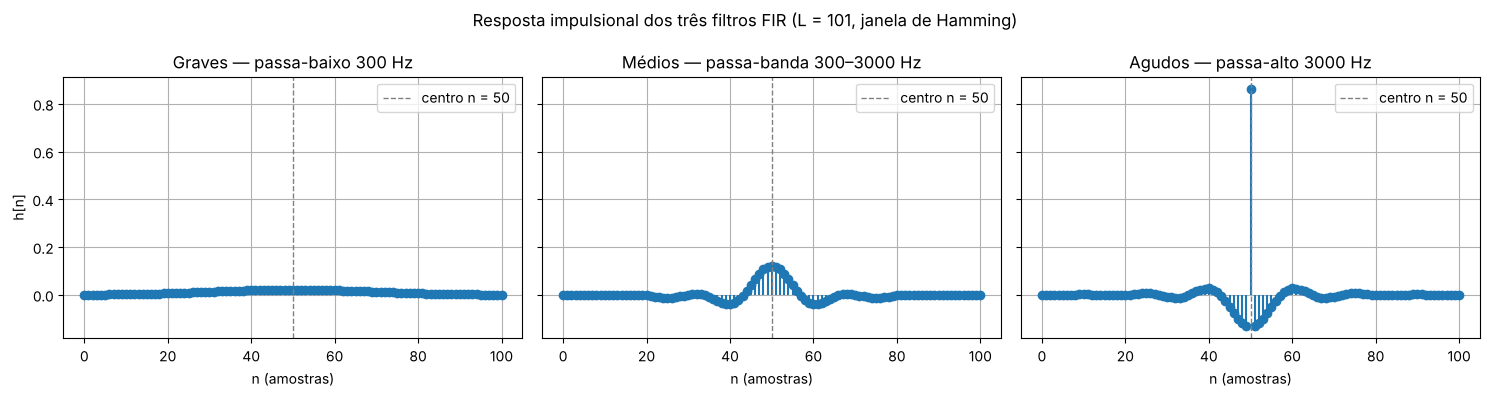

In [5]:
fig, axs = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
n = np.arange(L)
for ax, (h, nome) in zip(axs, FILTROS):
    ax.stem(n, h, basefmt=' ')
    ax.axvline(atraso, color='gray', ls='--', lw=1, label=f'centro n = {atraso}')
    ax.set_title(nome)
    ax.set_xlabel('n (amostras)')
    ax.legend(loc='upper right')
axs[0].set_ylabel('h[n]')
fig.suptitle('Resposta impulsional dos três filtros FIR (L = 101, janela de Hamming)')
plt.tight_layout(); plt.show()

**Interpretação**

- **Passa-baixo:** é uma sinc larga e quase sempre positiva. Os primeiros zeros da sinc ideal de 300 Hz estão a $\pm F_s/(2 f_{c1}) \approx \pm 73$ amostras do centro. A janela de 101 amostras ($\pm 50$) **nem sequer contém o lóbulo principal inteiro**. É esta truncagem severa que explica a fraca seletividade do filtro e a "fuga" de graves para o passa-banda.
- **Passa-alto:** tem um pico grande no centro ($h[50] \approx 1 - 2f_{c2}/F_s \approx 0{,}86$) e coeficientes pequenos e negativos à volta. Corresponde a um impulso menos um passa-baixo, $\delta[n-50] - h_{PB,3000}[n]$.
- **Passa-banda:** é proporcional à diferença entre dois passa-baixos, $h_{PB,3000}[n] - h_{PB,300}[n]$, e oscila à volta de zero.
- Todos os filtros são simétricos em torno de $n = 50$ e as extremidades tendem para zero por efeito da janela.

---
## 3. Resposta em frequência individual $|H(e^{j\omega})|$

A resposta em frequência é calculada com `scipy.signal.freqz`. Com `fs=Fs`, o eixo vem diretamente em Hz (de 0 até $F_s/2 = 22050$ Hz, a frequência de Nyquist). A magnitude é apresentada em dB, $|H|_{dB} = 20\log_{10}|H|$, e o eixo das frequências usa escala logarítmica, que corresponde melhor à perceção auditiva.

Valores de referência: 0 dB corresponde a ganho 1, −6 dB a ganho 0,5 e −60 dB a ganho 0,001.

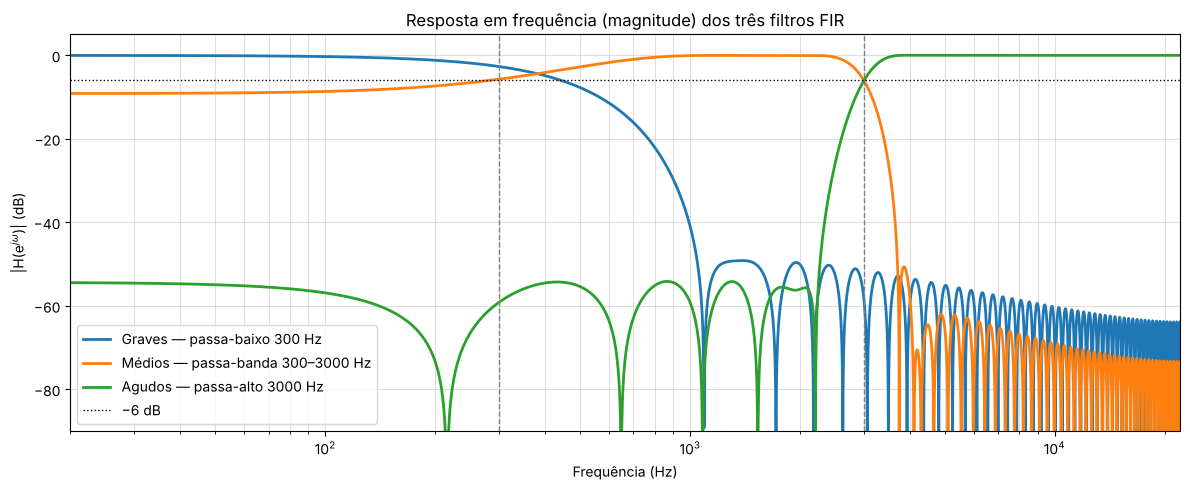

In [6]:
NPTS = 16384
fig, ax = plt.subplots(figsize=(12, 5))
for h, nome in FILTROS:
    f, H = freqz(h, worN=NPTS, fs=Fs)
    ax.semilogx(f[1:], db(H[1:]), lw=2, label=nome)
for fc in (fc1, fc2):
    ax.axvline(fc, color='gray', ls='--', lw=1)
ax.axhline(-6, color='k', ls=':', lw=1, label='−6 dB')
ax.set_xlim(20, Fs / 2); ax.set_ylim(-90, 5)
ax.set_xlabel('Frequência (Hz)'); ax.set_ylabel('|H(e$^{jω}$)| (dB)')
ax.set_title('Resposta em frequência (magnitude) dos três filtros FIR')
ax.grid(True, which='both', alpha=0.4); ax.legend(loc='lower left')
plt.tight_layout(); plt.show()

In [7]:
# Ganho (dB) de cada filtro em frequências de referência
f_ref = np.array([50, 100, 300, 600, 1000, 2000, 3000, 5000, 10000])
print(f'{"f (Hz)":>8s} | {"Graves":>8s} | {"Médios":>8s} | {"Agudos":>8s}')
print('-' * 44)
_, Hg = freqz(h_graves, worN=f_ref, fs=Fs)
_, Hm = freqz(h_medios, worN=f_ref, fs=Fs)
_, Ha = freqz(h_agudos, worN=f_ref, fs=Fs)
for i, f0 in enumerate(f_ref):
    print(f'{f0:8d} | {db(Hg[i]):8.1f} | {db(Hm[i]):8.1f} | {db(Ha[i]):8.1f}')

  f (Hz) |   Graves |   Médios |   Agudos
--------------------------------------------
      50 |     -0.1 |     -9.0 |    -54.9
     100 |     -0.3 |     -8.7 |    -56.9
     300 |     -2.7 |     -5.7 |    -59.1
     600 |    -11.4 |     -1.7 |    -63.6
    1000 |    -40.8 |     -0.1 |    -59.1
    2000 |    -50.0 |     -0.0 |    -56.0
    3000 |    -58.6 |     -6.1 |     -6.0
    5000 |    -55.2 |    -65.8 |      0.0
   10000 |    -70.1 |    -82.8 |     -0.0


**Interpretação**

- Cada filtro deixa passar (≈ 0 dB) a sua banda e atenua as restantes, até cerca de −50 a −60 dB, o valor típico da janela de Hamming.
- Em 3000 Hz, o passa-banda e o passa-alto estão ambos a ≈ −6 dB (ganho 0,5). Isto é próprio do método das janelas: o corte fica a meio da transição, e não a −3 dB como nos filtros analógicos clássicos. Em 300 Hz já não é assim (−2,7 dB no passa-baixo e −5,7 dB no passa-banda), porque a transição não "cabe" abaixo dessa frequência.
- **O passa-baixo de 300 Hz é muito pouco seletivo.** A 600 Hz ainda só atenua cerca de 11 dB, e só passa os −40 dB perto de 1 kHz.
- **O passa-banda não rejeita os graves.** Abaixo de 100 Hz está apenas a cerca de −9 dB, quando um filtro bem separado estaria abaixo de −50 dB. Na zona dos graves, os dois filtros sobrepõem-se. A causa está na secção 4.

---
## 4. Largura de transição e efeito da normalização do `firwin`

### 4.1 Largura de transição

Para a janela de Hamming, a largura da banda de transição de um FIR com $L$ coeficientes é aproximadamente:

$$\Delta f \approx \frac{3{,}3 \, F_s}{L} = \frac{3{,}3 \times 44100}{101} \approx 1440 \text{ Hz}$$

Esta largura não depende da frequência de corte. Uma transição de ~1,4 kHz é estreita em termos relativos no corte de 3000 Hz, mas é **mais larga do que toda a banda dos graves** (0–300 Hz). Por isso o passa-baixo não consegue separar bem os graves dos médios.

A célula seguinte mede a transição do passa-alto entre −50 dB (fim da banda de rejeição) e −0,1 dB (início da banda passante), compara-a com a fórmula e mostra o efeito de aumentar $L$.

L = 101: transição medida   2270 ->   3650 Hz  (Δf =  1379 Hz) | teórico 3,3·Fs/L =  1441 Hz
L = 201: transição medida   2639 ->   3326 Hz  (Δf =   687 Hz) | teórico 3,3·Fs/L =   724 Hz
L = 401: transição medida   2821 ->   3162 Hz  (Δf =   342 Hz) | teórico 3,3·Fs/L =   363 Hz


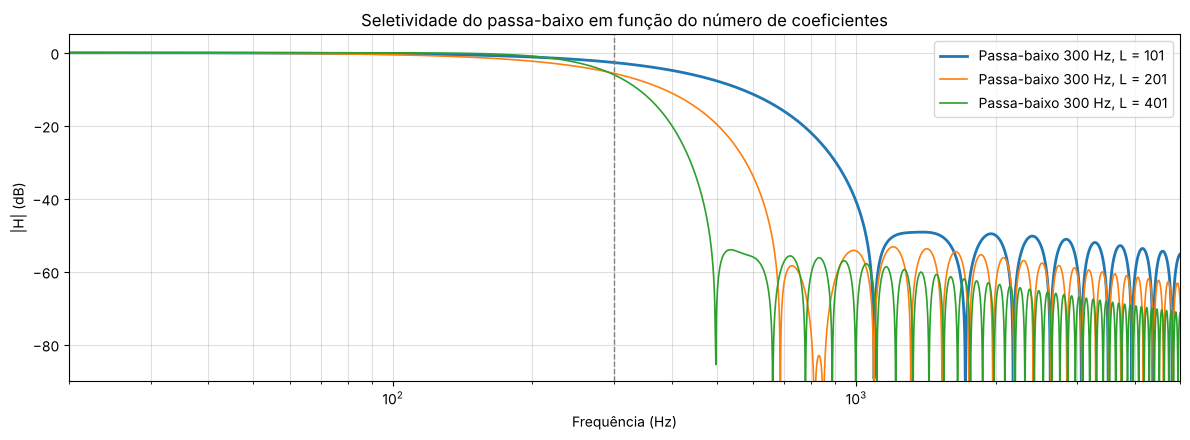

In [8]:
def largura_transicao_pa(h, fs=Fs, n=1 << 16):
    # Mede a transição de um passa-alto: de onde |H| sobe acima de -50 dB até onde chega a -0.1 dB.
    f, H = freqz(h, worN=n, fs=fs)
    HdB = db(H)
    f_rej = f[np.where(HdB < -50)[0].max()]    # última frequência ainda em rejeição
    f_pas = f[np.argmax((HdB > -0.1) & (f > f_rej))]
    return f_rej, f_pas, f_pas - f_rej

for Lt in (101, 201, 401):
    h_t = firwin(Lt, fc2, window=JANELA, fs=Fs, scale=ESCALA, pass_zero=False)
    f_rej, f_pas, df = largura_transicao_pa(h_t)
    print(f'L = {Lt:3d}: transição medida {f_rej:6.0f} -> {f_pas:6.0f} Hz  (Δf = {df:5.0f} Hz) | '
          f'teórico 3,3·Fs/L = {3.3*Fs/Lt:5.0f} Hz')

fig, ax = plt.subplots(figsize=(12, 4.5))
for Lt in (101, 201, 401):
    h_t = firwin(Lt, fc1, window=JANELA, fs=Fs, scale=ESCALA)
    f, H = freqz(h_t, worN=NPTS, fs=Fs)
    ax.semilogx(f[1:], db(H[1:]), lw=2 if Lt == L else 1.2, label=f'Passa-baixo {fc1} Hz, L = {Lt}')
ax.axvline(fc1, color='gray', ls='--', lw=1)
ax.set_xlim(20, 5000); ax.set_ylim(-90, 5)
ax.set_xlabel('Frequência (Hz)'); ax.set_ylabel('|H| (dB)')
ax.set_title('Seletividade do passa-baixo em função do número de coeficientes')
ax.grid(True, which='both', alpha=0.4); ax.legend()
plt.tight_layout(); plt.show()

**Interpretação**

- A largura medida bate com a previsão teórica $\Delta f \propto 1/L$: duplicar o número de coeficientes reduz a transição para metade.
- Um equalizador com graves bem separados precisaria de várias centenas de coeficientes. O custo seria um atraso maior, $(L-1)/2$ amostras, e mais operações por amostra. O enunciado fixa $L = 101$, e esta limitação deve ser tida em conta ao interpretar os resultados.

### 4.2 Sobreposição das bandas e o parâmetro `scale`

Idealmente, com $g_1 = g_2 = g_3 = 1$ o equalizador deixaria o sinal inalterado (resposta plana a 0 dB), e cada filtro teria ganho 1 na sua banda. Com $L = 101$ não é possível ter as duas coisas ao mesmo tempo. Compara-se o comportamento com `scale=True` (valor por omissão, usado neste trabalho) e com `scale=False`.

scale=True : ganho em 0 Hz -> passa-baixo 1.000, passa-banda 0.348, soma 1.348
scale=False: ganho em 0 Hz -> passa-baixo 0.653, passa-banda 0.349, soma 1.002


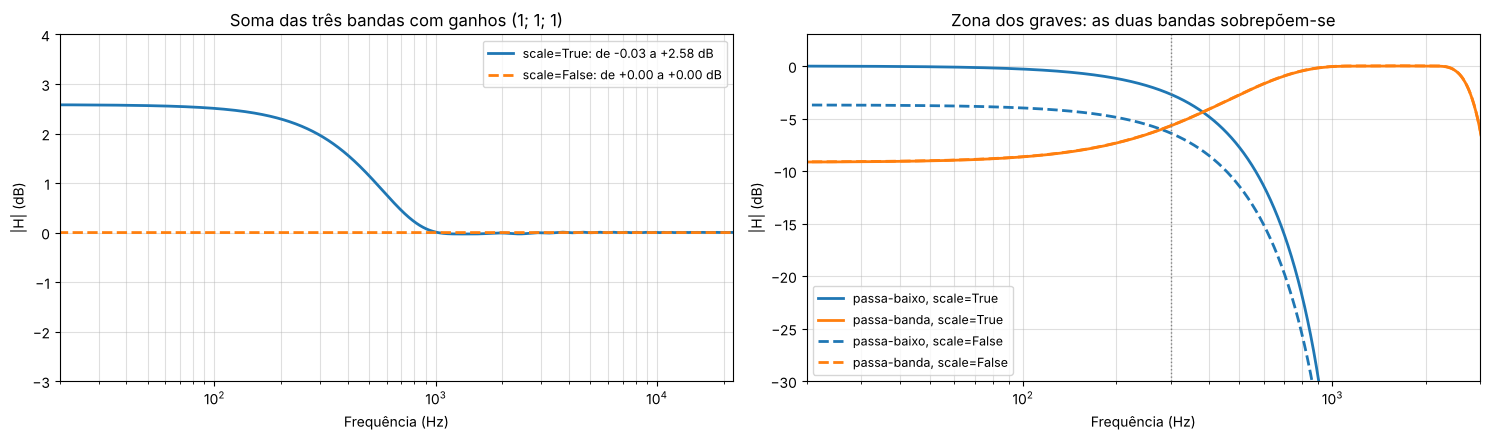

Com scale=False, h_graves + h_medios + h_agudos = δ[n-50]? True


In [9]:
def soma_bandas(scale):
    hg = firwin(L, fc1, window=JANELA, fs=Fs, scale=scale)
    hm = firwin(L, [fc1, fc2], window=JANELA, fs=Fs, scale=scale, pass_zero=False)
    ha = firwin(L, fc2, window=JANELA, fs=Fs, scale=scale, pass_zero=False)
    return hg + hm + ha

fig, axs = plt.subplots(1, 2, figsize=(15, 4.5))
for scale, estilo in ((True, '-'), (False, '--')):
    # Esquerda: soma das três bandas (ganhos unitários)
    f, H = freqz(soma_bandas(scale), worN=NPTS, fs=Fs)
    HdB = db(H)
    axs[0].semilogx(f[1:], HdB[1:], estilo, lw=2,
                    label=f'scale={scale}: de {HdB.min():+.2f} a {HdB.max():+.2f} dB')
    # Direita: passa-baixo e passa-banda individuais na zona dos graves
    hg = firwin(L, fc1, window=JANELA, fs=Fs, scale=scale)
    hm = firwin(L, [fc1, fc2], window=JANELA, fs=Fs, scale=scale, pass_zero=False)
    for h, nome, cor in ((hg, 'passa-baixo', 'C0'), (hm, 'passa-banda', 'C1')):
        f, H = freqz(h, worN=NPTS, fs=Fs)
        axs[1].semilogx(f[1:], db(H[1:]), estilo, color=cor, lw=2, label=f'{nome}, scale={scale}')
    print(f'scale={scale!s:5s}: ganho em 0 Hz -> passa-baixo {hg.sum():.3f}, passa-banda {hm.sum():.3f}, '
          f'soma {hg.sum() + hm.sum():.3f}')
axs[0].set_xlim(20, Fs / 2); axs[0].set_ylim(-3, 4)
axs[0].set_title('Soma das três bandas com ganhos (1; 1; 1)')
axs[1].set_xlim(20, 3000); axs[1].set_ylim(-30, 3)
axs[1].axvline(fc1, color='gray', ls=':', lw=1)
axs[1].set_title('Zona dos graves: as duas bandas sobrepõem-se')
for ax in axs:
    ax.set_xlabel('Frequência (Hz)'); ax.set_ylabel('|H| (dB)')
    ax.grid(True, which='both', alpha=0.4); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

h_soma = soma_bandas(False)
impulso_atrasado = np.zeros(L); impulso_atrasado[atraso] = 1
print('Com scale=False, h_graves + h_medios + h_agudos = δ[n-50]?', np.allclose(h_soma, impulso_atrasado))

**Interpretação**

- **Causa comum:** em 0 Hz o passa-banda tem ganho ≈ 0,35 nas duas versões. O seu flanco inferior (300 Hz) exigiria uma transição muito mais estreita do que os ~1,4 kHz possíveis com 101 coeficientes. Os graves passam, portanto, por **dois** filtros ao mesmo tempo.
- **`scale=True` (usado):** o passa-baixo tem ganho 1 em 0 Hz, ou seja, cada filtro cumpre isoladamente a especificação. Mas, com ganhos unitários, os graves somam $1 + 0{,}35 = 1{,}35$, o que dá **+2,6 dB** abaixo de ~300 Hz. Acima de ~1 kHz a soma é plana.
- **`scale=False`:** a soma é exatamente $\delta[n-50]$ e a resposta é perfeitamente plana, porque os filtros ideais são complementares, $H_{PB,300} + (H_{PB,3000} - H_{PB,300}) + (1 - H_{PB,3000}) = 1$, e a janela é linear e vale 1 no centro. O preço é que o passa-baixo só tem ganho ≈ 0,65 (−3,7 dB) em 0 Hz: a sinc truncada perde o lóbulo principal (secção 2), e os graves ficam repartidos entre 65% no passa-baixo e 35% no passa-banda.
- **Nenhuma das opções elimina a sobreposição**; só um $L$ maior o faz. Escolheu-se `scale=True` porque mantém cada filtro conforme à especificação. O desvio de +2,6 dB fica documentado. Para experimentar a alternativa, basta mudar `ESCALA = False` e voltar a correr o notebook.

---
## 5. Implementação do equalizador

Pela **linearidade** dos SLIT, há duas formas equivalentes de implementar o equalizador:

1. **Filtrar e somar:** $x_{eq} = g_1 (x * h_{graves}) + g_2 (x * h_{médios}) + g_3 (x * h_{agudos})$, ou seja, três filtragens.
2. **Filtro único:** constrói-se $h_{eq}[n] = g_1 h_{graves}[n] + g_2 h_{médios}[n] + g_3 h_{agudos}[n]$ e faz-se uma só filtragem, $x_{eq} = x * h_{eq}$. É mais eficiente e permite obter a resposta em frequência combinada com um único `freqz`.

As duas formas correspondem à associação de sistemas **em paralelo**: $h = h_1 + h_2$. A filtragem é feita com `lfilter(b, [1.0], x)`, que implementa a equação às diferenças de um FIR, $y[n] = \sum_k b_k x[n-k]$.

In [10]:
def h_equalizador(g1, g2, g3):
    # Resposta impulsional do equalizador completo (associação em paralelo dos 3 FIR).
    if min(g1, g2, g3) < 0:
        raise ValueError('Os ganhos têm de ser >= 0.')
    return g1 * h_graves + g2 * h_medios + g3 * h_agudos

def equalizador(x, g1, g2, g3):
    # Aplica o equalizador de 3 bandas ao sinal x. Devolve x_eq com o mesmo comprimento que x.
    return lfilter(h_equalizador(g1, g2, g3), [1.0], x)

def equalizador_3_filtros(x, g1, g2, g3):
    # Versão 'filtrar e somar', usada apenas para validar a equivalência.
    return (g1 * lfilter(h_graves, [1.0], x) +
            g2 * lfilter(h_medios, [1.0], x) +
            g3 * lfilter(h_agudos, [1.0], x))

# Validação com ruído branco
rng = np.random.default_rng(0)
x_teste = rng.standard_normal(Fs)
print('Filtro único == filtrar e somar?',
      np.allclose(equalizador(x_teste, *BASS_BOOST), equalizador_3_filtros(x_teste, *BASS_BOOST)))

Filtro único == filtrar e somar? True


---
## 6. Resposta em frequência combinada

Compara-se a resposta do equalizador completo $H_{eq}(e^{j\omega}) = g_1 H_{graves} + g_2 H_{médios} + g_3 H_{agudos}$ em três configurações:

| Configuração | $(g_1, g_2, g_3)$ | Ganho ideal (graves / médios / agudos) |
| :--- | :--- | :--- |
| Plano | (1; 1; 1) | 0 / 0 / 0 dB |
| *Bass Boost* | (2; 1; 0,5) | +6 / 0 / −6 dB |
| *Treble Boost* | (0,5; 1; 2) | −6 / 0 / +6 dB |

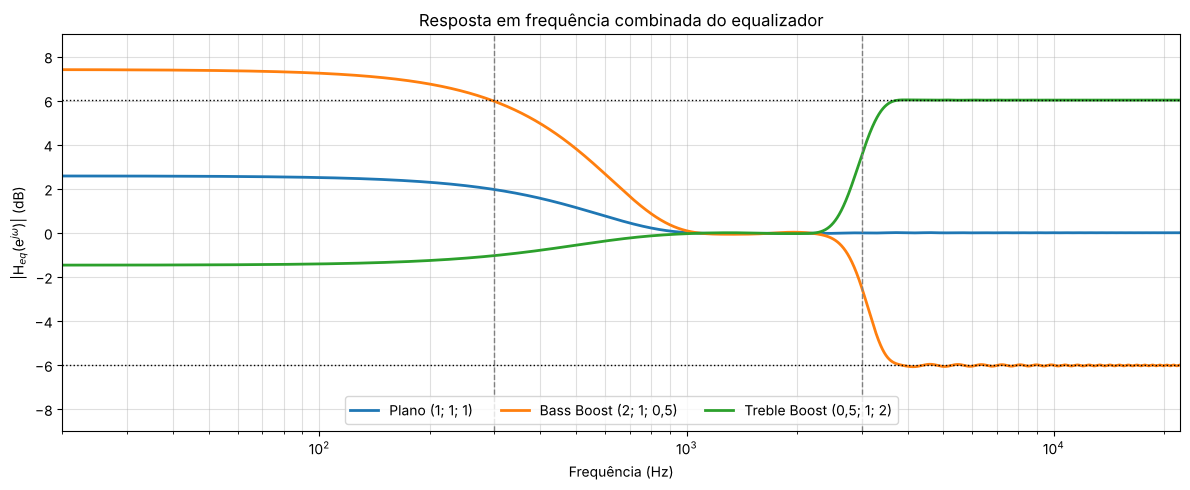

  f (Hz) |          Plano (1; 1; 1) |   Bass Boost (2; 1; 0,5) | Treble Boost (0,5; 1; 2)
      50 |                 +2.56 dB |                 +7.37 dB |                 -1.46 dB
     300 |                 +1.96 dB |                 +5.97 dB |                 -1.04 dB
    1000 |                 +0.01 dB |                 +0.09 dB |                 -0.04 dB
    3000 |                 -0.00 dB |                 -2.49 dB |                 +3.52 dB
   10000 |                 +0.00 dB |                 -6.01 dB |                 +6.02 dB


In [11]:
CONFIGS = [(GANHOS_PLANO, 'Plano (1; 1; 1)'),
           (BASS_BOOST,   'Bass Boost (2; 1; 0,5)'),
           (TREBLE_BOOST, 'Treble Boost (0,5; 1; 2)')]

fig, ax = plt.subplots(figsize=(12, 5))
for ganhos, nome in CONFIGS:
    f, H = freqz(h_equalizador(*ganhos), worN=NPTS, fs=Fs)
    ax.semilogx(f[1:], db(H[1:]), lw=2, label=nome)
for fc in (fc1, fc2):
    ax.axvline(fc, color='gray', ls='--', lw=1)
for nivel in (6.02, -6.02):
    ax.axhline(nivel, color='k', ls=':', lw=1)
ax.set_xlim(20, Fs / 2); ax.set_ylim(-9, 9)
ax.set_xlabel('Frequência (Hz)'); ax.set_ylabel('|H$_{eq}$(e$^{jω}$)| (dB)')
ax.set_title('Resposta em frequência combinada do equalizador')
ax.grid(True, which='both', alpha=0.4); ax.legend(loc='lower center', ncol=3)
plt.tight_layout(); plt.show()

print(f'{"f (Hz)":>8s} | ' + ' | '.join(f'{nome:>24s}' for _, nome in CONFIGS))
for f0 in (50, 300, 1000, 3000, 10000):
    linha = []
    for ganhos, _ in CONFIGS:
        _, H0 = freqz(h_equalizador(*ganhos), worN=[f0], fs=Fs)
        linha.append(f'{db(H0[0]):+21.2f} dB')
    print(f'{f0:8d} | ' + ' | '.join(linha))

**Interpretação**

- **Agudos:** comportamento ideal. Em 10 kHz obtêm-se exatamente +6,02 dB ($20\log_{10}2$) no Treble Boost e −6,02 dB ($20\log_{10}0{,}5$) no Bass Boost, e a zona dos médios fica a 0 dB.
- **Graves:** os valores afastam-se do ideal por causa da sobreposição da secção 4.2. Em 50 Hz, o ganho é $g_1 \cdot 1 + g_2 \cdot 0{,}35$:
    - Bass Boost: $2 + 0{,}35 = 2{,}35$, ou seja, **+7,4 dB** em vez de +6 dB;
    - Treble Boost: $0{,}5 + 0{,}35 = 0{,}85$, ou seja, apenas **−1,5 dB** em vez de −6 dB;
    - Plano: $1{,}35$, ou seja, +2,6 dB.
- **As transições entre patamares são graduais**, por causa da largura de transição de ~1,4 kHz (secção 4). Em 3000 Hz a mudança parece mais abrupta porque 1,4 kHz é pequeno face a 3000 Hz. À volta de 300 Hz, a mesma largura cobre várias oitavas.
- Como os ganhos podem ser superiores a 1, o sinal equalizado pode ultrapassar a amplitude 1. A normalização trata disso (secção 8).

---
## 7. Validação no domínio do tempo com sinusóides

Propriedade fundamental de um SLIT: se a entrada for uma sinusóide de frequência $f_0$, a saída é uma sinusóide **da mesma frequência**, com a amplitude multiplicada por $|H(e^{j\omega_0})|$ e a fase deslocada.

Para validar o equalizador sem recorrer ao `freqz`, geram-se tons de amplitude 1 em várias frequências e mede-se a amplitude de saída em regime estacionário, ou seja, depois de as primeiras $L$ amostras de transitório terem passado. O resultado compara-se com o $|H|$ teórico.

In [12]:
t = np.arange(Fs) / Fs          # 1 segundo
f_tons = [100, 300, 1000, 3000, 8000]

for ganhos, nome in CONFIGS[1:]:   # Bass Boost e Treble Boost
    print(f'\n{nome}')
    print(f'{"f0 (Hz)":>8s} | {"A medida":>9s} | {"|H| teórico":>11s} | {"erro (dB)":>9s}')
    _, H_teo = freqz(h_equalizador(*ganhos), worN=f_tons, fs=Fs)
    for f0, Ht in zip(f_tons, H_teo):
        x_tom = np.sin(2 * np.pi * f0 * t)
        y_tom = equalizador(x_tom, *ganhos)
        A = np.max(np.abs(y_tom[2 * L:]))           # ignora o transitório inicial
        print(f'{f0:8d} | {A:9.4f} | {abs(Ht):11.4f} | {db(A) - db(Ht):9.3f}')


Bass Boost (2; 1; 0,5)
 f0 (Hz) |  A medida | |H| teórico | erro (dB)
     100 |    2.3022 |      2.3022 |    -0.000
     300 |    1.9874 |      1.9875 |    -0.000
    1000 |    1.0107 |      1.0107 |    -0.000
    3000 |    0.7503 |      0.7504 |    -0.000
    8000 |    0.5015 |      0.5015 |    -0.000

Treble Boost (0,5; 1; 2)
 f0 (Hz) |  A medida | |H| teórico | erro (dB)
     100 |    0.8498 |      0.8498 |    -0.000
     300 |    0.8876 |      0.8876 |    -0.000
    1000 |    0.9954 |      0.9954 |    -0.000
    3000 |    1.4993 |      1.4994 |    -0.000
    8000 |    2.0001 |      2.0001 |    -0.000


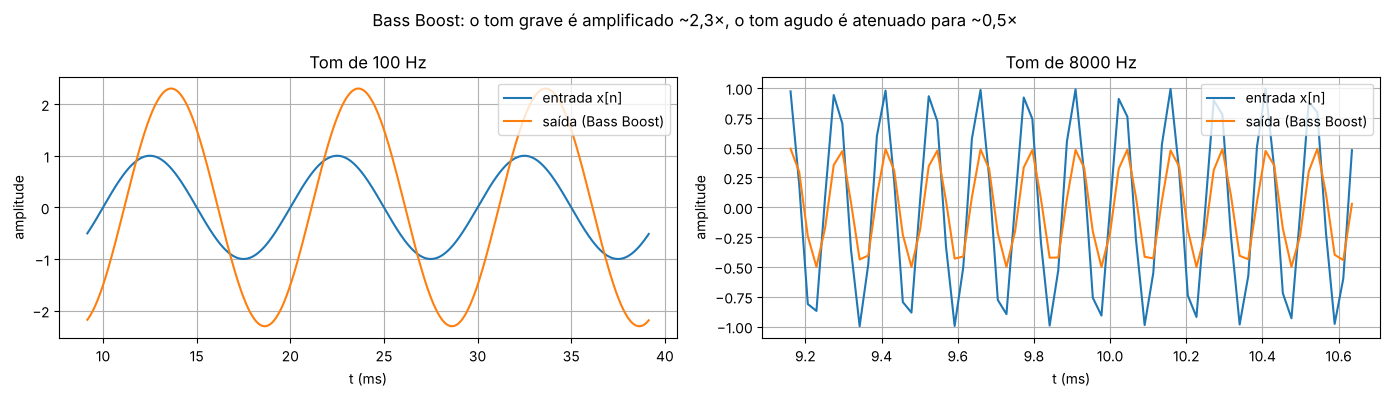

In [13]:
# Visualização: tons de 100 Hz e 8000 Hz antes e depois do Bass Boost
fig, axs = plt.subplots(1, 2, figsize=(14, 4))
for ax, f0, janela_ms in zip(axs, (100, 8000), (30, 1.5)):
    x_tom = np.sin(2 * np.pi * f0 * t)
    y_tom = equalizador(x_tom, *BASS_BOOST)
    i0 = 4 * L; i1 = i0 + ms2amostras(janela_ms)
    tt = 1000 * t[i0:i1]
    ax.plot(tt, x_tom[i0:i1], label='entrada x[n]')
    ax.plot(tt, y_tom[i0:i1], label='saída (Bass Boost)')
    ax.set_title(f'Tom de {f0} Hz'); ax.set_xlabel('t (ms)'); ax.set_ylabel('amplitude')
    ax.legend(loc='upper right')
plt.suptitle('Bass Boost: o tom grave é amplificado ~2,3×, o tom agudo é atenuado para ~0,5×')
plt.tight_layout(); plt.show()

**Interpretação**

- As amplitudes medidas coincidem com $|H|$ teórico (erros da ordem de centésimas de dB). A análise no domínio da frequência e o comportamento real no tempo são, portanto, consistentes.
- Nos gráficos, a frequência de saída é a mesma da entrada; só mudam a amplitude e a fase. Vê-se também o **atraso de 50 amostras** (≈ 1,13 ms), mais visível no tom de 8000 Hz.
- Nas frequências de corte (300 e 3000 Hz), o ganho fica a meio caminho entre os ganhos das duas bandas vizinhas, porque cada filtro está a −6 dB nesse ponto.

---
## 8. Prevenção de *clipping*

Os sinais de áudio em vírgula flutuante devem estar no intervalo $[-1, 1]$. Ao reproduzir ou gravar em 16 bits, os valores fora deste intervalo são cortados (*clipping*), o que se ouve como distorção. Com ganhos superiores a 1, o sinal equalizado pode exceder este limite.

A solução é **normalizar pelo pico**: $x_{eq} \leftarrow 0{,}99 \cdot x_{eq} / \max|x_{eq}|$. A forma do sinal não muda; só muda o volume global. Usa-se 0,99 em vez de 1 para deixar uma pequena margem.

In [14]:
x_demo = 0.9 * normalizar(rng.standard_normal(Fs // 2))     # ruído com pico 0,9
for ganhos, nome in CONFIGS[1:]:
    y = equalizador(x_demo, *ganhos)
    y_n = normalizar(y)
    print(f'{nome:26s}: pico antes = {np.max(np.abs(y)):.3f} | '
          f'amostras > 1: {np.sum(np.abs(y) > 1):5d} | pico após normalizar = {np.max(np.abs(y_n)):.3f}')

Bass Boost (2; 1; 0,5)    : pico antes = 0.622 | amostras > 1:     0 | pico após normalizar = 0.990
Treble Boost (0,5; 1; 2)  : pico antes = 1.687 | amostras > 1:   401 | pico após normalizar = 0.990


---
## 9. Teste auditivo

O efeito audível do equalizador é avaliado com dois tipos de sinal:

1. **Sinal sintético:** um tom de 100 Hz (grave), um de 1000 Hz (médio) e um de 8000 Hz (agudo), seguidos de ruído branco, que contém todas as frequências. Permite ouvir cada banda isoladamente.
2. **Áudio real:** se existirem `audio/voz.wav` e `audio/percussao.wav` (mono, 44100 Hz, sons secos), são processados com as três configurações e gravados na pasta `audio/`.

Também se mostra o **espetro** (magnitude da FFT) do ruído branco antes e depois da equalização. Como o ruído branco tem espetro plano, o espetro da saída reproduz a forma de $|H_{eq}|$.

In [15]:
def tom(f0, dur=1.0, A=0.5):
    tt = np.arange(int(dur * Fs)) / Fs
    env = np.minimum(1, np.minimum(tt, tt[::-1]) / 0.02)    # rampas de 20 ms para evitar estalidos
    return A * env * np.sin(2 * np.pi * f0 * tt)

silencio = np.zeros(int(0.25 * Fs))
ruido = 0.5 * normalizar(rng.standard_normal(2 * Fs))   # pico 0,5
x_sint = np.concatenate([tom(100), silencio, tom(1000), silencio, tom(8000), silencio, ruido])

print('Original'); display(Audio(x_sint, rate=Fs, normalize=False))
for ganhos, nome in CONFIGS[1:]:
    y = normalizar(equalizador(x_sint, *ganhos))
    print(nome); display(Audio(y, rate=Fs, normalize=False))

Original


Bass Boost (2; 1; 0,5)


Treble Boost (0,5; 1; 2)


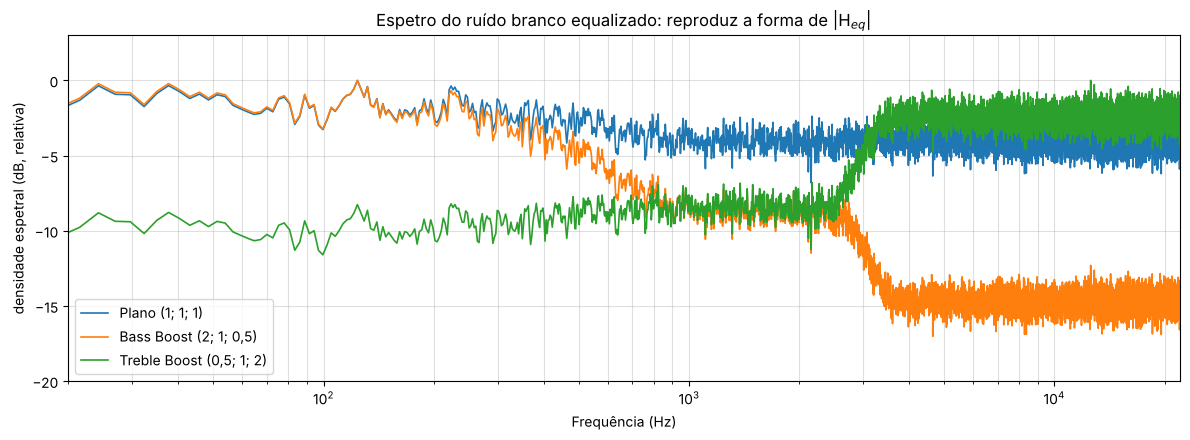

In [16]:
# Espetro do ruído branco antes e depois da equalização
def espetro_db(x, nfft=1 << 14):
    # Espetro médio (método de Welch simplificado): média de |FFT|^2 em segmentos com janela de Hann.
    seg = [x[i:i + nfft] * np.hanning(nfft) for i in range(0, len(x) - nfft, nfft // 2)]
    P = np.mean([np.abs(np.fft.rfft(s)) ** 2 for s in seg], axis=0)
    return np.fft.rfftfreq(nfft, 1 / Fs), 10 * np.log10(P / P.max() + 1e-12)

ruido_longo = rng.standard_normal(10 * Fs)
fig, ax = plt.subplots(figsize=(12, 4.5))
for ganhos, nome in CONFIGS:
    f, P = espetro_db(equalizador(ruido_longo, *ganhos))
    ax.semilogx(f[1:], P[1:], lw=1.2, label=nome)
ax.set_xlim(20, Fs / 2); ax.set_ylim(-20, 3)
ax.set_xlabel('Frequência (Hz)'); ax.set_ylabel('densidade espetral (dB, relativa)')
ax.set_title('Espetro do ruído branco equalizado: reproduz a forma de |H$_{eq}$|')
ax.grid(True, which='both', alpha=0.4); ax.legend()
plt.tight_layout(); plt.show()

In [17]:
# Áudio real (se os ficheiros existirem na pasta audio/)
FICHEIROS = {'voz': os.path.join(PASTA_AUDIO, 'voz.wav'),
             'percussao': os.path.join(PASTA_AUDIO, 'percussao.wav')}

for nome_sinal, caminho in FICHEIROS.items():
    if not os.path.exists(caminho):
        print(f'[aviso] {caminho} não encontrado — coloque um .wav mono a 44100 Hz com este nome.')
        continue
    x = ler_wav(caminho)
    print(f'\n=== {nome_sinal} ({len(x)/Fs:.1f} s) — original ===')
    display(Audio(np.clip(x, -1, 1), rate=Fs, normalize=False))
    for ganhos, nome in CONFIGS[1:]:
        y = normalizar(equalizador(x, *ganhos))
        sufixo = 'bass' if ganhos == BASS_BOOST else 'treble'
        gravar_wav(os.path.join(PASTA_AUDIO, f'{nome_sinal}_eq_{sufixo}.wav'), y)
        print(nome); display(Audio(y, rate=Fs, normalize=False))

[aviso] audio/voz.wav não encontrado — coloque um .wav mono a 44100 Hz com este nome.
[aviso] audio/percussao.wav não encontrado — coloque um .wav mono a 44100 Hz com este nome.


**O que se deve ouvir**

- **Bass Boost:** o tom de 100 Hz fica mais forte e o de 8000 Hz mais fraco. O ruído soa mais "abafado" e escuro.
- **Treble Boost:** o contrário. O tom de 8000 Hz destaca-se e o ruído soa mais "brilhante" e sibilante.
- O tom de 1000 Hz mantém o volume relativo nas duas configurações, porque $g_2 = 1$. Em termos absolutos pode parecer diferente, por causa da normalização pelo pico.
- Na voz, o Bass Boost realça o corpo e a ressonância do peito, e o Treble Boost realça as consoantes sibilantes (s, f, ch). Na percussão, o Bass Boost realça o bombo e o Treble Boost realça os pratos e o ataque das baquetas.

---
## 10. Conclusões da Parte A

1. Projetaram-se três filtros FIR de fase linear ($L = 101$, janela de Hamming) que dividem o espetro em graves (< 300 Hz), médios (300–3000 Hz) e agudos (> 3000 Hz). Todos têm o mesmo atraso de 50 amostras (≈ 1,13 ms).
2. **Limitação principal:** a largura de transição da janela de Hamming ($\Delta f \approx 3{,}3 F_s / L \approx 1{,}4$ kHz) é maior do que toda a banda dos graves. O passa-banda deixa passar cerca de 35% dos graves (−9 dB), e as duas bandas sobrepõem-se abaixo de ~1 kHz. Separá-las bem exigiria mais coeficientes (por exemplo, $L = 401$ dá $\Delta f \approx 360$ Hz), à custa de mais atraso e mais cálculo.
3. Por causa dessa sobreposição, não é possível ter ao mesmo tempo cada filtro com ganho 1 na sua banda e a soma das bandas plana. Com `scale=True` (escolhido) os filtros cumprem a especificação, mas a configuração plana tem +2,6 dB nos graves. Com `scale=False` a soma é exatamente $\delta[n-50]$, mas o passa-baixo fica a −3,7 dB.
4. Nos agudos, o Bass Boost e o Treble Boost produzem exatamente os ±6 dB esperados. Nos graves obtém-se +7,4 dB e −1,5 dB, em vez de ±6 dB, pelo mesmo motivo. O teste com sinusóides confirmou no domínio do tempo os valores de $|H|$ obtidos com `freqz`.
5. A normalização pelo pico garante que o sinal de saída nunca excede ±1, o que elimina o *clipping* quando os ganhos são superiores a 1.

*Nota: reescreva estas conclusões com as suas palavras e confirme os valores com os resultados da sua execução. A discussão oral avalia a compreensão, não o texto.*